# 03 · Causal Interventions

*Causal interventions workstream.*

`PROPOSAL.md` § 4.5 validates and tests features with three intervention types: **ablation**,
**amplification/clamping**, and **cross-prompt activation patching**. This notebook demonstrates all
three directly on GPT-2 small, using TransformerLens hooks, the same mechanism, just applied to a whole
hook point instead of one SAE feature.


In [1]:
import torch
from transformer_lens import HookedTransformer

torch.manual_seed(0)
model = HookedTransformer.from_pretrained("gpt2", device="cpu")

def top_prediction(logits):
    probs = torch.softmax(logits[0, -1, :], dim=-1)
    p, t = probs.max(dim=-1)
    return model.to_string(t.item()), p.item()


/tmp/ipykernel_3539/2835263832.py:5: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device="cpu")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2 into HookedTransformer


## 1. Ablation

Zero out one attention head's contribution entirely and see whether the model's top prediction changes.
Most individual heads won't matter much for a given prompt (that's normal: most of a model's capacity
is redundant or used elsewhere); we're demonstrating the *mechanism*, not hunting for a dramatic effect.


In [2]:
prompt = "Water is made of hydrogen and"
tokens = model.to_tokens(prompt)

baseline_logits = model(tokens)
word, p = top_prediction(baseline_logits)
print(f"baseline top prediction: {word!r} (p={p:.3f})")

LAYER, HEAD = 9, 6

def zero_head(activation, hook):
    activation[:, :, HEAD, :] = 0.0
    return activation

ablated_logits = model.run_with_hooks(
    tokens,
    fwd_hooks=[(f"blocks.{LAYER}.attn.hook_z", zero_head)],
)
word, p = top_prediction(ablated_logits)
print(f"after ablating layer {LAYER} head {HEAD}: {word!r} (p={p:.3f})")


baseline top prediction: ' oxygen' (p=0.484)
after ablating layer 9 head 6: ' oxygen' (p=0.455)


## 2. Amplification / clamping

Instead of zeroing an activation, scale it up (amplify) or pin it to a fixed value (clamp). Here we
amplify the same head's output several-fold.


In [3]:
def amplify_head(activation, hook, factor=8.0):
    activation[:, :, HEAD, :] *= factor
    return activation

amplified_logits = model.run_with_hooks(
    tokens,
    fwd_hooks=[(f"blocks.{LAYER}.attn.hook_z", amplify_head)],
)
word, p = top_prediction(amplified_logits)
print(f"after amplifying layer {LAYER} head {HEAD} 8x: {word!r} (p={p:.3f})")


after amplifying layer 9 head 6 8x: ' oxygen' (p=0.592)


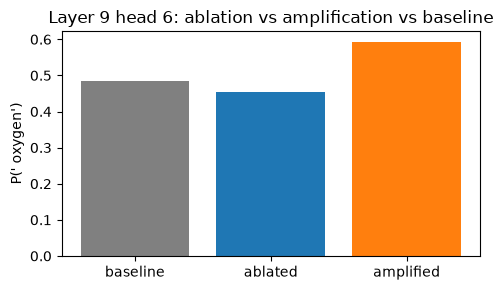

In [4]:
import matplotlib.pyplot as plt

oxygen_token = model.to_single_token(" oxygen")

def oxygen_prob(logits):
    return torch.softmax(logits[0, -1, :], dim=-1)[oxygen_token].item()

fig, ax = plt.subplots(figsize=(5, 3))
conditions = ["baseline", "ablated", "amplified"]
probs = [oxygen_prob(baseline_logits), oxygen_prob(ablated_logits), oxygen_prob(amplified_logits)]
ax.bar(conditions, probs, color=["gray", "tab:blue", "tab:orange"])
ax.set_ylabel("P(' oxygen')")
ax.set_title(f"Layer {LAYER} head {HEAD}: ablation vs amplification vs baseline")
plt.tight_layout()
plt.show()


## 3. Cross-prompt activation patching

The classic causal-tracing move: run the model on two prompts that differ in one detail, cache prompt
A's activations, then run prompt B but *patch in* prompt A's activation at one layer. If that layer
carries the detail, prompt B's output should shift toward prompt A's answer. We use a version of the
"indirect object identification" task from the interpretability literature: swap which name is doing the
giving, and see whether patching one layer's residual stream flips who the model expects to receive the
drink.


In [5]:
prompt_a = "When John and Mary went to the store, John gave a drink to"   # model should say Mary
prompt_b = "When Mary and John went to the store, Mary gave a drink to"  # model should say John

tokens_a = model.to_tokens(prompt_a)
tokens_b = model.to_tokens(prompt_b)
assert tokens_a.shape == tokens_b.shape, "toy example assumes matching token lengths"

_, cache_a = model.run_with_cache(tokens_a)

word, p = top_prediction(model(tokens_b))
print(f"prompt B baseline: {word!r} (p={p:.3f})")

PATCH_LAYER = 9

def patch_from_a(activation, hook):
    activation[:, -1, :] = cache_a[f"blocks.{PATCH_LAYER}.hook_resid_post"][:, -1, :]
    return activation

patched_logits = model.run_with_hooks(
    tokens_b,
    fwd_hooks=[(f"blocks.{PATCH_LAYER}.hook_resid_post", patch_from_a)],
)
word, p = top_prediction(patched_logits)
print(f"prompt B with layer {PATCH_LAYER}'s last-token residual patched from prompt A: {word!r} (p={p:.3f})")


prompt B baseline: ' John' (p=0.411)
prompt B with layer 9's last-token residual patched from prompt A: ' Mary' (p=0.283)


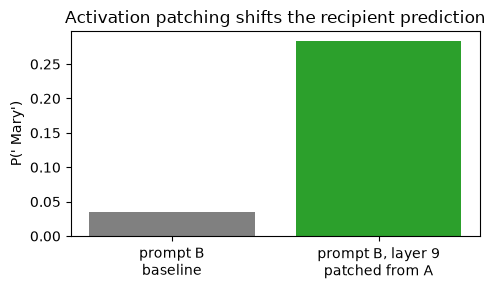

In [6]:
mary_token = model.to_single_token(" Mary")

def mary_prob(logits):
    return torch.softmax(logits[0, -1, :], dim=-1)[mary_token].item()

fig, ax = plt.subplots(figsize=(5, 3))
conditions = ["prompt B\nbaseline", f"prompt B, layer {PATCH_LAYER}\npatched from A"]
probs = [mary_prob(model(tokens_b)), mary_prob(patched_logits)]
ax.bar(conditions, probs, color=["gray", "tab:green"])
ax.set_ylabel("P(' Mary')")
ax.set_title("Activation patching shifts the recipient prediction")
plt.tight_layout()
plt.show()


Prompt B's baseline answer is "John," but once we patch in prompt A's layer-9 residual stream, the
top prediction flips to "Mary," the same name prompt A itself predicts, even though the confidence is
lower than prompt A's own (patching one layer's worth of information isn't the same as running prompt A
outright). That layer's residual stream at that position is carrying real information about which name
the sentence is about to name as the recipient. Try changing `PATCH_LAYER` to an earlier layer (say, 3 or
4) and rerun the cell; you'll see little to no shift, which tells you this particular piece of
information isn't represented there yet. Different facts and different models localize at different
depths, which is itself the kind of thing a real circuit-tracing investigation (`PROPOSAL.md` § 4.6)
maps out systematically.


## What you should take away

- All three intervention types are the same basic move: register a hook at some point in the forward
  pass, mutate the activation flowing through it, and compare the output to the unmodified run.
- Ablation asks "does this matter at all?", amplification asks "what happens if this matters *more*?",
  and patching asks "does this specific value, from a specific other run, carry the effect?", three
  different questions, same mechanism.
- `PROPOSAL.md` § 4.5 applies exactly this toolkit to SAE *features* instead of raw attention heads, to
  test whether a candidate self-correction or premise-commitment feature actually drives behavior.
